In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load Test Split
npz_path = "/content/drive/MyDrive/TerraSpectra/data/patches/terraspectra_patches.npz"
data = np.load(npz_path)

X_test_raw = data["X_test"]  # (1538, 15, 15, 30)
y_test = data["y_test"]      # (1538,)

X_t = np.expand_dims(np.transpose(X_test_raw, (0, 3, 1, 2)), axis=1)  # (1538, 1, 30, 15, 15)
test_loader = DataLoader(
    TensorDataset(torch.tensor(X_t, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long)),
    batch_size=64,
    shuffle=False,
)

# Official 16 Indian Pines Class Names
INDIAN_PINES_CLASSES = [
    "Alfalfa", "Corn-notill", "Corn-mintill", "Corn",
    "Grass-pasture", "Grass-trees", "Grass-pasture-mowed", "Hay-windrowed",
    "Oats", "Soybean-notill", "Soybean-mintill", "Soybean-clean",
    "Wheat", "Woods", "Buildings-Grass-Trees", "Stone-Steel-Towers"
]
print(f"Loaded {len(y_test)} test samples across {len(INDIAN_PINES_CLASSES)} crop/land classes.")

Using device: cuda
Loaded 1538 test samples across 16 crop/land classes.


In [2]:
class Spectral3DViTFusion(nn.Module):
    def __init__(self, num_classes=16, embed_dim=128, num_heads=4, num_layers=2, dropout=0.2):
        super().__init__()
        self.conv3d = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=(7, 3, 3)),
            nn.BatchNorm3d(8),
            nn.GELU(),
            nn.Conv3d(8, 16, kernel_size=(5, 3, 3)),
            nn.BatchNorm3d(16),
            nn.GELU(),
            nn.Conv3d(16, 32, kernel_size=(3, 3, 3)),
            nn.BatchNorm3d(32),
            nn.GELU(),
        )
        num_tokens = 9 * 9
        self.token_proj = nn.Linear(32 * 18, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.randn(1, num_tokens + 1, embed_dim) * 0.02)
        self.pos_drop = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 2,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, return_attention=False):
        x = self.conv3d(x)
        b, c, d, h, w = x.shape
        x = x.view(b, c * d, h * w).transpose(1, 2)
        x = self.token_proj(x)
        cls_tokens = self.cls_token.expand(b, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.pos_drop(x + self.pos_embed)

        attn_maps = []
        if return_attention:
            for layer in self.transformer.layers:
                # Pre-norm self-attention with explicit attention weights
                x_norm = layer.norm1(x)
                attn_out, attn_w = layer.self_attn(
                    x_norm, x_norm, x_norm, need_weights=True, average_attn_weights=False
                )
                x = x + layer.dropout1(attn_out)
                x = x + layer._ff_block(layer.norm2(x))
                attn_maps.append(attn_w)  # Shape: (B, num_heads, 82, 82)
        else:
            x = self.transformer(x)

        logits = self.head(self.norm(x[:, 0]))
        if return_attention:
            return logits, attn_maps
        return logits

SAVE_DIR = "/content/drive/MyDrive/TerraSpectra/data/artifacts"
MODEL_PATH = f"{SAVE_DIR}/vit_fusion_tuned_day8.pth"

model = Spectral3DViTFusion(num_classes=16).to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print("Loaded Day 8 tuned weights successfully!")

/tmp/ipykernel_464/2996383110.py:30: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Loaded Day 8 tuned weights successfully!


=== DAY 9 COMPREHENSIVE EVALUATION ===
Overall Accuracy (OA):  99.80%
Average Accuracy (AA):  99.65%
Cohen's Kappa Score:    0.9978
Macro F1-Score:         99.38%
Weighted F1-Score:      99.81%

                       precision    recall  f1-score   support

              Alfalfa     1.0000    1.0000    1.0000         7
          Corn-notill     1.0000    1.0000    1.0000       214
         Corn-mintill     0.9921    1.0000    0.9960       125
                 Corn     1.0000    1.0000    1.0000        35
        Grass-pasture     1.0000    1.0000    1.0000        73
          Grass-trees     1.0000    1.0000    1.0000       110
  Grass-pasture-mowed     1.0000    1.0000    1.0000         4
        Hay-windrowed     1.0000    1.0000    1.0000        71
                 Oats     1.0000    1.0000    1.0000         3
       Soybean-notill     1.0000    1.0000    1.0000       146
      Soybean-mintill     1.0000    1.0000    1.0000       369
        Soybean-clean     1.0000    0.9775    0.

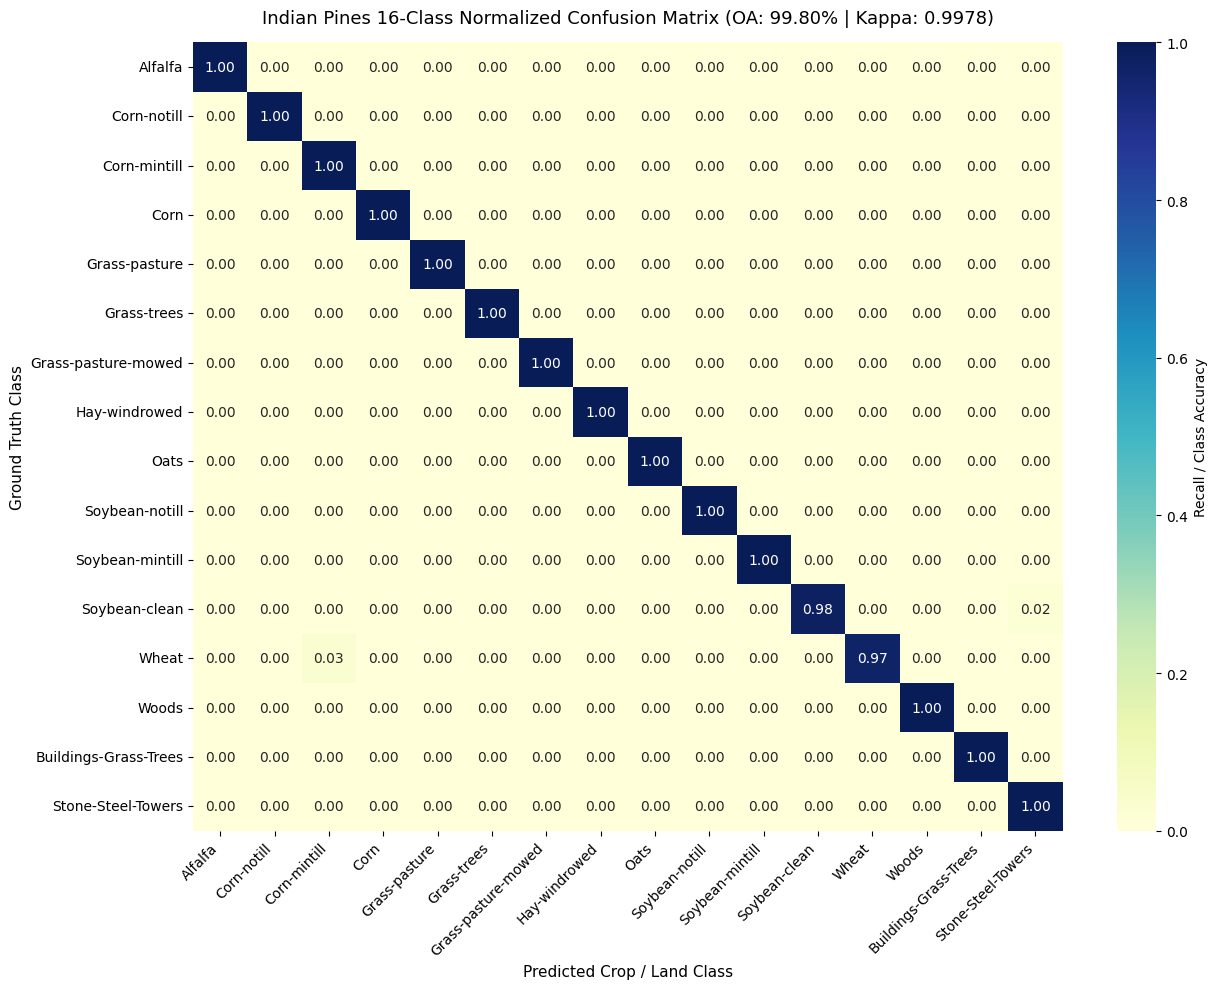

Saved -> /content/drive/MyDrive/TerraSpectra/data/artifacts/confusion_matrix_day9.png & evaluation_report_day9.json


In [3]:
all_preds, all_targets = [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        preds = model(X_b).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(y_b.numpy())

oa = accuracy_score(all_targets, all_preds) * 100
kappa = cohen_kappa_score(all_targets, all_preds)
macro_f1 = f1_score(all_targets, all_preds, average="macro") * 100
weighted_f1 = f1_score(all_targets, all_preds, average="weighted") * 100

cm = confusion_matrix(all_targets, all_preds)
per_class_acc = (cm.diagonal() / cm.sum(axis=1)) * 100
aa = np.mean(per_class_acc)

print("=== DAY 9 COMPREHENSIVE EVALUATION ===")
print(f"Overall Accuracy (OA):  {oa:.2f}%")
print(f"Average Accuracy (AA):  {aa:.2f}%")
print(f"Cohen's Kappa Score:    {kappa:.4f}")
print(f"Macro F1-Score:         {macro_f1:.2f}%")
print(f"Weighted F1-Score:      {weighted_f1:.2f}%\n")
print(classification_report(all_targets, all_preds, target_names=INDIAN_PINES_CLASSES, digits=4))

# Plot Normalized Confusion Matrix
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(13, 10))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=INDIAN_PINES_CLASSES,
    yticklabels=INDIAN_PINES_CLASSES,
    cbar_kws={"label": "Recall / Class Accuracy"}
)
plt.title(f"Indian Pines 16-Class Normalized Confusion Matrix (OA: {oa:.2f}% | Kappa: {kappa:.4f})", fontsize=13, pad=14)
plt.xlabel("Predicted Crop / Land Class", fontsize=11)
plt.ylabel("Ground Truth Class", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = f"{SAVE_DIR}/confusion_matrix_day9.png"
plt.savefig(cm_path, dpi=180)
plt.show()

# Save Full JSON Evaluation Report
report_dict = classification_report(all_targets, all_preds, target_names=INDIAN_PINES_CLASSES, output_dict=True)
eval_summary = {
    "model": "Spectral3DViTFusion (Day 8 Tuned)",
    "overall_accuracy_pct": round(float(oa), 2),
    "average_accuracy_pct": round(float(aa), 2),
    "cohen_kappa": round(float(kappa), 4),
    "macro_f1_pct": round(float(macro_f1), 2),
    "weighted_f1_pct": round(float(weighted_f1), 2),
    "per_class_metrics": report_dict
}
with open(f"{SAVE_DIR}/evaluation_report_day9.json", "w") as f:
    json.dump(eval_summary, f, indent=2)

print(f"Saved -> {cm_path} & evaluation_report_day9.json")

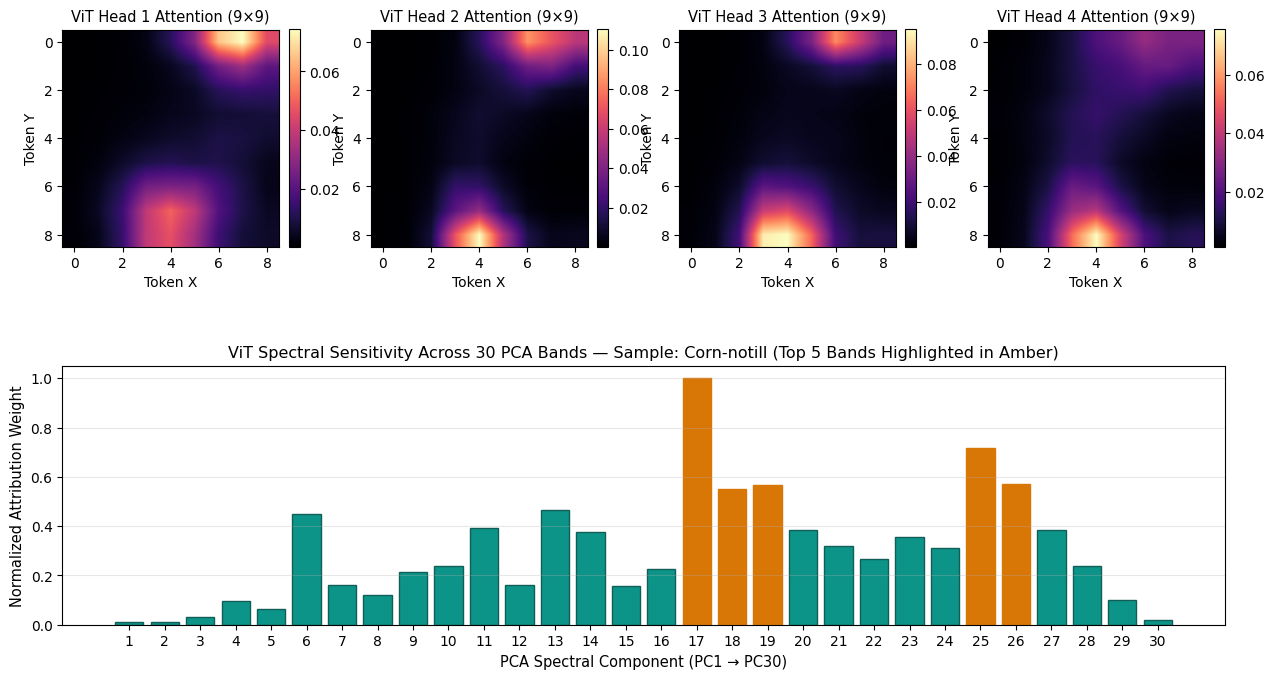

Saved ViT Explainability plot -> /content/drive/MyDrive/TerraSpectra/data/artifacts/vit_attention_explainability_day9.png


In [4]:
# 1. Extract Multi-Head Attention on a representative Corn-notill / Soybean patch
sample_idx = np.where(y_test == 1)[0][0]  # Class 1: Corn-notill
sample_tensor = torch.tensor(X_t[sample_idx:sample_idx+1], dtype=torch.float32, device=device, requires_grad=True)

logits, attn_maps = model(sample_tensor, return_attention=True)
pred_class = logits.argmax(1).item()

# Layer 2 (final transformer layer) attention from [CLS] token (index 0) to 81 spatial tokens (1..81)
# Shape: (4 heads, 81) -> reshape to (4, 9, 9)
last_layer_attn = attn_maps[-1][0, :, 0, 1:].detach().cpu().numpy().reshape(4, 9, 9)

# 2. Gradient-based Spectral Band Importance across 30 PCA components
logits[0, pred_class].backward()
# sample_tensor.grad shape: (1, 1, 30, 15, 15) -> mean absolute gradient per PCA band (30,)
spectral_importance = sample_tensor.grad.abs().mean(dim=(0, 1, 3, 4)).cpu().numpy()
spectral_importance = spectral_importance / spectral_importance.max()

# Plot Combined Explainability Figure
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 4, hspace=0.38, wspace=0.3)

# Top Row: 4 Attention Heads on 9x9 Token Grid
for h in range(4):
    ax = fig.add_subplot(gs[0, h])
    im = ax.imshow(last_layer_attn[h], cmap="magma", interpolation="bilinear")
    ax.set_title(f"ViT Head {h+1} Attention (9×9)", fontsize=10.5)
    ax.set_xlabel("Token X")
    ax.set_ylabel("Token Y")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Bottom Row: PCA Spectral Band Sensitivity (PC1 - PC30)
ax_spec = fig.add_subplot(gs[1, :])
bars = ax_spec.bar(range(1, 31), spectral_importance, color="#0d9488", edgecolor="#115e59")
top_bands = np.argsort(spectral_importance)[-5:]
for idx in top_bands:
    bars[idx].set_color("#d97706")

ax_spec.set_title(
    f"ViT Spectral Sensitivity Across 30 PCA Bands — Sample: {INDIAN_PINES_CLASSES[pred_class]} (Top 5 Bands Highlighted in Amber)",
    fontsize=11.5
)
ax_spec.set_xlabel("PCA Spectral Component (PC1 → PC30)", fontsize=10.5)
ax_spec.set_ylabel("Normalized Attribution Weight", fontsize=10.5)
ax_spec.set_xticks(range(1, 31))
ax_spec.grid(axis="y", alpha=0.3)

attn_plot_path = f"{SAVE_DIR}/vit_attention_explainability_day9.png"
plt.savefig(attn_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved ViT Explainability plot -> {attn_plot_path}")